# Pipeline del modelo final: detección temprana de riesgo de depresión

Estudiantes: Nicoll Quesada, Daniel Hurtado y Santiago Lozano.

Este notebook **no vuelve a buscar hiperparámetros**. Toma el mejor modelo encontrado en `Entrenamiento_de_Red_Neuronal_Proyecto-4.ipynb` y lo organiza como un pipeline reproducible de punta a punta: carga, preparación, entrenamiento, predicción con umbral, evaluación, persistencia e inferencia sobre registros nuevos.

**Modelo final:** MLP `[32]` | AdaGrad | lr = 0.05 | sin L1/L2 | dropout 0.1 | early stopping | escalado MinMax | umbral de decisión 0.40.

**Estructura del repositorio**

```
proyecto/
├── datos/            data_with_depression_risk.csv
├── notebooks/        pipeline.ipynb (este archivo)
├── src/              pipeline_riesgo.py (las mismas funciones de este notebook, para usarlas sin él)
├── modelos/          artefactos guardados: pesos, escalador, columnas, umbral y metadatos
├── reportes/figuras/ diagrama del pipeline y figuras de evaluación
├── requirements.txt
└── README.md
```

## 1. Configuración centralizada

Todos los valores que definen el pipeline están en un solo lugar: semilla, arquitectura, hiperparámetros, umbral y rutas. Cada valor viene de un experimento del notebook 4 (ver la tabla de trazabilidad en la sección 7). Si se cambia algo aquí, el resto del pipeline lo toma automáticamente.

In [1]:
import copy
import json
import random
import re
import sys
from dataclasses import dataclass, asdict
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import sklearn
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

In [2]:
# Raíz del repositorio (el notebook vive en notebooks/)
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()


@dataclass(frozen=True)
class Config:
    semilla: int = 42
    # Partición (estratificada)
    test_size: float = 0.20
    val_size: float = 0.20            # fracción de entrenamiento que se reserva para validación
    # Modelo final (mejor configuración del pipeline de 216 corridas)
    arquitectura: tuple = (32,)
    dropout: float = 0.1
    optimizador: str = "AdaGrad"
    learning_rate: float = 0.05
    batch_size: int = 32
    # Early stopping
    max_epocas: int = 150
    paciencia: int = 15
    min_delta: float = 1e-4
    # Decisión
    umbral: float = 0.40              # elegido en validación (maximiza el F1 de la clase 1)
    # Perceptrón de referencia
    perceptron_optimizador: str = "SGD"
    perceptron_learning_rate: float = 0.01
    # Rutas
    ruta_datos: Path = RAIZ / "datos" / "data_with_depression_risk.csv"
    ruta_modelos: Path = RAIZ / "modelos"
    ruta_figuras: Path = RAIZ / "reportes" / "figuras"


CFG = Config()

**Reproducibilidad.** `fijar_semilla` fija las semillas de `random`, `numpy` y `torch` y activa los algoritmos deterministas. También se usa un solo hilo de CPU, que con redes tan pequeñas es más rápido y evita diferencias numéricas entre ejecuciones. Con esto, el entrenamiento reproduce exactamente el modelo del notebook 4. Las versiones de las librerías se imprimen abajo y están fijadas en `requirements.txt`.

In [3]:
def fijar_semilla(semilla=CFG.semilla):
    """Fija todas las fuentes de aleatoriedad para que el entrenamiento sea reproducible."""
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.use_deterministic_algorithms(True, warn_only=True)


torch.set_num_threads(1)
fijar_semilla()

In [4]:
CFG.ruta_modelos.mkdir(parents=True, exist_ok=True)
CFG.ruta_figuras.mkdir(parents=True, exist_ok=True)

VERSIONES = {"python": sys.version.split()[0], "torch": torch.__version__, "numpy": np.__version__,
             "pandas": pd.__version__, "scikit-learn": sklearn.__version__, "joblib": joblib.__version__}
display(pd.Series(VERSIONES, name="versión").to_frame())
display(pd.Series({k: str(v) for k, v in asdict(CFG).items()}, name="valor").to_frame())

,versión
python,3.12.8
torch,2.2.2
numpy,1.26.4
pandas,2.2.3
scikit-learn,1.6.1
joblib,1.4.2


,valor
semilla,42
test_size,0.2
val_size,0.2
arquitectura,"(32,)"
dropout,0.1
optimizador,AdaGrad
learning_rate,0.05
batch_size,32
max_epocas,150
paciencia,15


## 2. Diagrama de flujo del pipeline

El diagrama muestra las nueve etapas y cómo se conectan. Los datos se preparan una sola vez y se parten en tres conjuntos. El escalador se **ajusta solo con entrenamiento** y se reutiliza en validación, prueba e inferencia (flechas punteadas). La validación sirve para el early stopping y para elegir el umbral, y la prueba solo se usa en la evaluación final. La figura se guarda en `reportes/figuras/diagrama_pipeline.png` para el informe y el video.

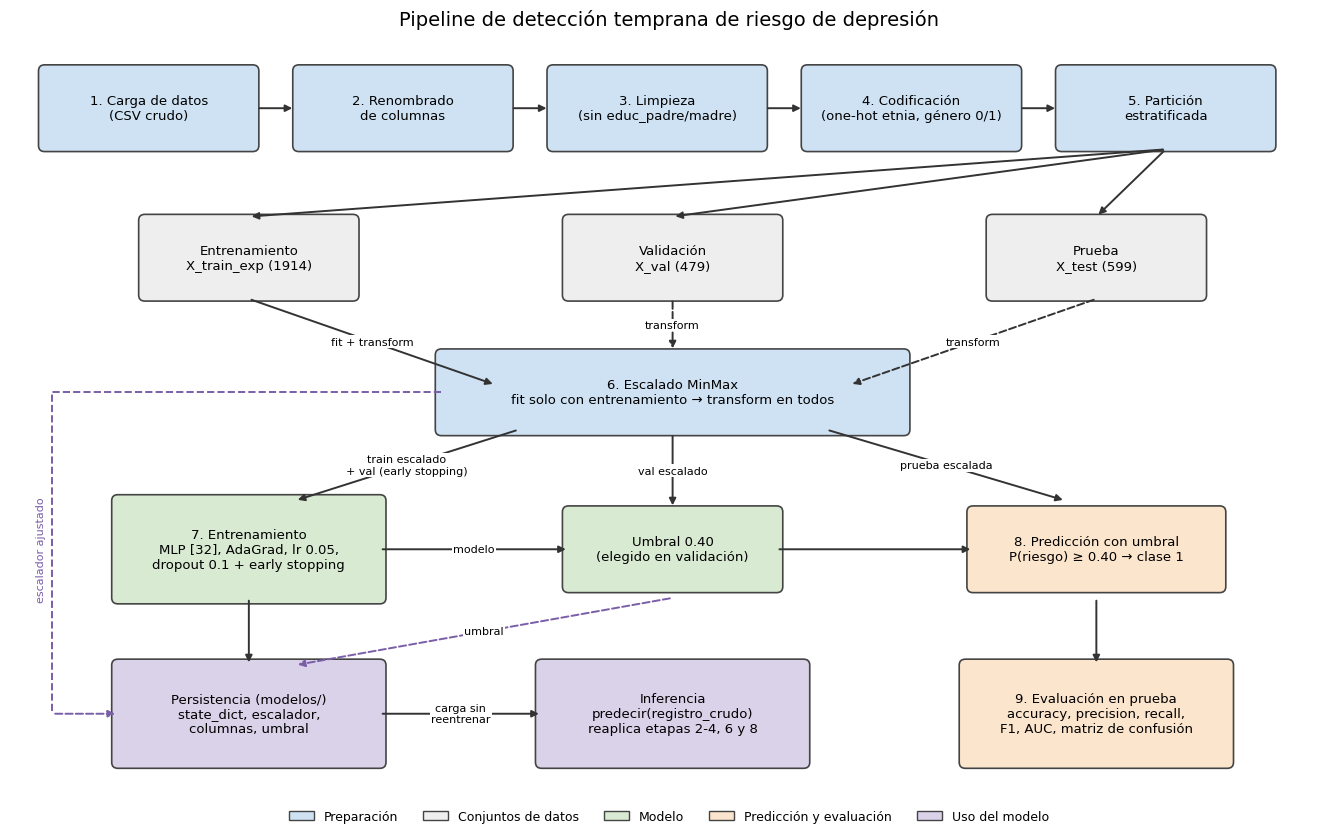

In [5]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

COLORES = {"prep": "#cfe2f3", "datos": "#eeeeee", "modelo": "#d9ead3", "eval": "#fce5cd", "uso": "#d9d2e9"}


def caja(ax, x, y, texto, tipo, ancho=2.7, alto=1.0):
    ax.add_patch(FancyBboxPatch((x - ancho / 2, y - alto / 2), ancho, alto, boxstyle="round,pad=0.08",
                                facecolor=COLORES[tipo], edgecolor="#444444", linewidth=1.2))
    ax.text(x, y, texto, ha="center", va="center", fontsize=9.5)


def flecha(ax, x0, y0, x1, y1, texto=None, estilo="-", color="#333333"):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0),
                arrowprops=dict(arrowstyle="-|>", color=color, lw=1.4, linestyle=estilo, shrinkA=2, shrinkB=2))
    if texto:
        ax.text((x0 + x1) / 2, (y0 + y1) / 2, texto, fontsize=8, ha="center", va="center",
                bbox=dict(facecolor="white", edgecolor="none", pad=1))


fig, ax = plt.subplots(figsize=(17, 10))
ax.set_xlim(-0.1, 17)
ax.set_ylim(0, 10.3)
ax.axis("off")

# Fila 1: preparación de los datos
etapas = ["1. Carga de datos\n(CSV crudo)", "2. Renombrado\nde columnas", "3. Limpieza\n(sin educ_padre/madre)",
          "4. Codificación\n(one-hot etnia, género 0/1)", "5. Partición\nestratificada"]
xs = [1.7, 5.0, 8.3, 11.6, 14.9]
for x, t in zip(xs, etapas):
    caja(ax, x, 9.3, t, "prep")
for x0, x1 in zip(xs[:-1], xs[1:]):
    flecha(ax, x0 + 1.4, 9.3, x1 - 1.4, 9.3)

# Fila 2: conjuntos
conjuntos = {"Entrenamiento\nX_train_exp (1914)": 3.0, "Validación\nX_val (479)": 8.5, "Prueba\nX_test (599)": 14.0}
for t, x in conjuntos.items():
    caja(ax, x, 7.3, t, "datos")
    flecha(ax, 14.9, 8.75, x, 7.85)

# Fila 3: escalado
caja(ax, 8.5, 5.5, "6. Escalado MinMax\nfit solo con entrenamiento → transform en todos", "prep", ancho=6.0)
flecha(ax, 3.0, 6.75, 6.2, 5.6, "fit + transform")
flecha(ax, 8.5, 6.75, 8.5, 6.05, "transform", estilo="--")
flecha(ax, 14.0, 6.75, 10.8, 5.6, "transform", estilo="--")

# Fila 4: modelo, umbral y predicción
caja(ax, 3.0, 3.4, "7. Entrenamiento\nMLP [32], AdaGrad, lr 0.05,\ndropout 0.1 + early stopping", "modelo", ancho=3.4, alto=1.3)
caja(ax, 8.5, 3.4, "Umbral 0.40\n(elegido en validación)", "modelo")
caja(ax, 14.0, 3.4, "8. Predicción con umbral\nP(riesgo) ≥ 0.40 → clase 1", "eval", ancho=3.2)
flecha(ax, 6.5, 5.0, 3.6, 4.05, "train escalado\n+ val (early stopping)")
flecha(ax, 8.5, 4.95, 8.5, 3.95, "val escalado")
flecha(ax, 10.5, 5.0, 13.6, 4.05, "prueba escalada")
flecha(ax, 4.7, 3.4, 7.15, 3.4, "modelo")
flecha(ax, 9.85, 3.4, 12.4, 3.4)

# Fila 5: evaluación, persistencia e inferencia
caja(ax, 14.0, 1.2, "9. Evaluación en prueba\naccuracy, precision, recall,\nF1, AUC, matriz de confusión", "eval", ancho=3.4, alto=1.3)
caja(ax, 3.0, 1.2, "Persistencia (modelos/)\nstate_dict, escalador,\ncolumnas, umbral", "uso", ancho=3.4, alto=1.3)
caja(ax, 8.5, 1.2, "Inferencia\npredecir(registro_crudo)\nreaplica etapas 2-4, 6 y 8", "uso", ancho=3.4, alto=1.3)
flecha(ax, 14.0, 2.75, 14.0, 1.85)
flecha(ax, 3.0, 2.75, 3.0, 1.85)
flecha(ax, 4.7, 1.2, 6.8, 1.2, "carga sin\nreentrenar")
# El escalador ajustado va a persistencia por el borde izquierdo (sin cruzar otras cajas)
ax.plot([5.5, 0.45, 0.45], [5.5, 5.5, 1.2], linestyle="--", color="#7a5ea8", lw=1.4)
flecha(ax, 0.45, 1.2, 1.3, 1.2, estilo="--", color="#7a5ea8")
ax.text(0.3, 3.4, "escalador ajustado", rotation=90, fontsize=8, color="#7a5ea8", ha="center", va="center")
flecha(ax, 8.5, 2.75, 3.6, 1.85, "umbral", estilo="--", color="#7a5ea8")

leyenda = [FancyBboxPatch((0, 0), 1, 1, facecolor=c, edgecolor="#444444") for c in COLORES.values()]
ax.legend(leyenda, ["Preparación", "Conjuntos de datos", "Modelo", "Predicción y evaluación", "Uso del modelo"],
          loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.04), fontsize=9, frameon=False)
ax.set_title("Pipeline de detección temprana de riesgo de depresión", fontsize=14)
fig.savefig(CFG.ruta_figuras / "diagrama_pipeline.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Etapas del pipeline

Cada etapa es una función con un nombre claro, para que se pueda ejecutar, probar y explicar por separado. Las etapas 2 a 4 no aprenden nada de los datos (son reglas fijas), así que se aplican igual a la base completa y a un registro nuevo. La etapa 6 sí aprende (mínimos y máximos), por eso se ajusta solo con entrenamiento.

### Etapas 1 a 3: carga, renombrado y limpieza

- **Carga:** lee el CSV original sin modificarlo.
- **Renombrado:** las columnas originales son las preguntas completas de la encuesta. Se reemplazan por nombres cortos según el número de la pregunta (por ejemplo, `16.3 ...` → `pss_3`).
- **Limpieza:** se eliminan `educ_padre` y `educ_madre`, que tienen más del 30 % de faltantes (954 y 1059 de 2992) que no se pueden imputar de forma confiable.

In [6]:
OBJETIVO = "riesgo_dep"

PREGUNTAS = {
    "1": "anio_nac", "2": "genero", "3": "estrato", "4": "etnia",
    "5.1": "educ_padre", "5.2": "educ_madre",
    "6": "satisf_vida", "7": "felicidad_ayer", "8": "risa_ayer", "9": "aprendio_ayer",
    "10": "disfrute_ayer", "11": "preocupacion_ayer", "12": "depresion_ayer",
    "13": "ira_ayer", "14": "estres_ayer", "15": "soledad",
    **{f"16.{i}": f"pss_{i}" for i in range(1, 11)},   # PSS-10: estrés percibido (0-4)
    **{f"17.{i}": f"gad_{i}" for i in range(1, 8)},    # GAD-7: ansiedad (0-3)
}
COLUMNAS_ELIMINADAS = ["educ_padre", "educ_madre"]


def cargar_datos(ruta=CFG.ruta_datos):
    """Etapa 1: lee el CSV crudo."""
    return pd.read_csv(ruta)


def renombrar_columnas(df):
    """Etapa 2: cambia cada pregunta por un nombre corto según su número.
    Las columnas que ya tienen nombre corto no cambian."""
    def nombre_corto(columna):
        columna = columna.strip()
        if columna.lower().startswith("riesgo"):
            return OBJETIVO
        numero = re.match(r"^(\d+(?:\.\d+)?)", columna)
        return PREGUNTAS.get(numero.group(1), columna) if numero else columna
    return df.rename(columns=nombre_corto)


def limpiar(df):
    """Etapa 3: elimina las columnas de educación de los padres (>30 % de faltantes, MNAR)."""
    return df.drop(columns=COLUMNAS_ELIMINADAS, errors="ignore")

### Etapa 4: codificación

`etnia` usa códigos del 1 al 6 que no tienen orden, así que se convierte en 6 columnas binarias (*one-hot*). Las categorías están fijas, de modo que un registro nuevo siempre genera las mismas 6 columnas aunque solo tenga una etnia. `genero` pasa de {1, 2} a {0, 1}.

In [7]:
ETNIAS = {1: "indigena", 2: "gitano", 3: "raizal", 4: "palenquero", 5: "afrocolombiano", 6: "ninguno"}
COLUMNAS_ETNIA = [f"etnia_{v}" for v in ETNIAS.values()]


def codificar(df):
    """Etapa 4: one-hot de etnia (6 columnas fijas) y género a 0/1."""
    df = df.copy()
    df["genero"] = df["genero"].map({1: 0, 2: 1})
    dummies = pd.get_dummies(df["etnia"].map(ETNIAS), prefix="etnia", dtype=int)
    dummies = dummies.reindex(columns=COLUMNAS_ETNIA, fill_value=0)
    return pd.concat([df.drop(columns="etnia"), dummies], axis=1)


def preparar(df_crudo):
    """Etapas 2 a 4 juntas: del CSV crudo a variables numéricas."""
    return codificar(limpiar(renombrar_columnas(df_crudo)))

### Etapa 5: partición estratificada

Primero se separa el 20 % para **prueba**, que solo se usa en la evaluación final. Después se separa el 20 % del resto para **validación**, que se usa para el early stopping y para elegir el umbral. Ambas particiones son estratificadas, así que los tres conjuntos conservan la proporción de la clase 1 (≈ 35.7 %). La validación se separa **antes** de escalar, lo que evita la fuga de información que tenía la primera versión del notebook.

In [8]:
def particionar(df, cfg=CFG):
    """Etapa 5: entrenamiento / validación / prueba, estratificado (64 % / 16 % / 20 %)."""
    X = df.drop(columns=OBJETIVO)
    y = df[OBJETIVO].astype(int)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=cfg.test_size, random_state=cfg.semilla, stratify=y)
    X_tr, X_val, y_tr, y_val = train_test_split(
        X_train, y_train, test_size=cfg.val_size, random_state=cfg.semilla, stratify=y_train)
    return {"train": (X_tr, y_tr), "val": (X_val, y_val), "test": (X_test, y_test)}

### Etapa 6: escalado MinMax sin fuga de información

El escalador aprende el mínimo y el máximo de cada variable no binaria **solo con el conjunto de entrenamiento**. Ese mismo escalador ya ajustado se aplica a validación, prueba y a cualquier registro nuevo, así que ningún dato fuera de entrenamiento influye en la transformación. Las columnas binarias (`genero` y las de `etnia`) ya están en 0/1 y no se escalan.

In [9]:
COLUMNAS_BINARIAS = ["genero"] + COLUMNAS_ETNIA


def ajustar_escalador(X_train):
    """Etapa 6a: ajusta MinMaxScaler SOLO con entrenamiento (variables no binarias)."""
    columnas = [c for c in X_train.columns if c not in COLUMNAS_BINARIAS]
    return MinMaxScaler().fit(X_train[columnas].astype(float))


def escalar(X, escalador):
    """Etapa 6b: aplica el escalador ya ajustado (validación, prueba o inferencia)."""
    X = X.astype(float).copy()
    columnas = list(escalador.feature_names_in_)
    X[columnas] = escalador.transform(X[columnas])
    return X


def a_tensores(X, y=None):
    X_t = torch.tensor(X.values, dtype=torch.float32)
    return X_t if y is None else (X_t, torch.tensor(np.asarray(y), dtype=torch.float32).view(-1, 1))

### Etapa 7: modelo y entrenamiento con early stopping

La red tiene una capa oculta de 32 neuronas ReLU con dropout 0.1 y una neurona de salida que entrega un logit. La sigmoide se aplica dentro de `BCEWithLogitsLoss`, que es numéricamente más estable. En cada época se mide la pérdida en validación. Si no mejora en 15 épocas seguidas el entrenamiento se detiene y se **restauran los pesos de la mejor época**. Con `arquitectura=()` la misma clase es el perceptrón de referencia.

In [10]:
class MLP(nn.Module):
    """Red con capas ocultas ReLU (+ dropout opcional) y 1 neurona de salida (logit)."""

    def __init__(self, n_entradas, arquitectura, dropout=0.0):
        super().__init__()
        capas, previo = [], n_entradas
        for n in arquitectura:
            capas += [nn.Linear(previo, n), nn.ReLU()]
            if dropout > 0:
                capas.append(nn.Dropout(dropout))
            previo = n
        capas.append(nn.Linear(previo, 1))
        self.network = nn.Sequential(*capas)

    def forward(self, x):
        return self.network(x)


def crear_modelo(n_entradas, arquitectura=CFG.arquitectura, dropout=CFG.dropout):
    fijar_semilla()   # mismos pesos iniciales en cada ejecución
    return MLP(n_entradas, arquitectura, dropout)


def entrenar(modelo, X_tr, y_tr, X_val, y_val, optimizador="AdaGrad", lr=CFG.learning_rate, cfg=CFG):
    """Etapa 7: entrena con mini-batches y early stopping sobre la pérdida de validación."""
    opt = (torch.optim.Adagrad if optimizador == "AdaGrad" else torch.optim.SGD)(modelo.parameters(), lr=lr)
    criterio = nn.BCEWithLogitsLoss()
    fijar_semilla()
    lotes = DataLoader(TensorDataset(X_tr, y_tr), batch_size=cfg.batch_size, shuffle=True,
                       generator=torch.Generator().manual_seed(cfg.semilla))
    historial = {"train_loss": [], "val_loss": []}
    mejor, mejor_epoca, mejor_estado, sin_mejora = float("inf"), 0, None, 0

    for epoca in range(1, cfg.max_epocas + 1):
        modelo.train()
        for X_b, y_b in lotes:
            opt.zero_grad()
            criterio(modelo(X_b), y_b).backward()
            opt.step()
        modelo.eval()
        with torch.no_grad():
            historial["train_loss"].append(criterio(modelo(X_tr), y_tr).item())
            perdida_val = criterio(modelo(X_val), y_val).item()
        historial["val_loss"].append(perdida_val)
        if perdida_val < mejor - cfg.min_delta:
            mejor, mejor_epoca, mejor_estado, sin_mejora = perdida_val, epoca, copy.deepcopy(modelo.state_dict()), 0
        else:
            sin_mejora += 1
            if sin_mejora >= cfg.paciencia:
                break

    modelo.load_state_dict(mejor_estado)
    modelo.eval()
    return {"historial": historial, "mejor_epoca": mejor_epoca, "epoca_parada": epoca}

### Etapas 8 y 9: predicción con umbral y evaluación

El modelo entrega la probabilidad de riesgo. Un estudiante se clasifica en riesgo cuando esa probabilidad es **mayor o igual a 0.40**, no 0.5. Bajar el umbral detecta más estudiantes en riesgo a cambio de algunas falsas alarmas, y en una detección temprana es peor no detectar un caso. La evaluación reporta accuracy, precision, recall, F1 de la clase 1 y AUC.

In [11]:
def predecir_proba(modelo, X_t):
    """Probabilidad de riesgo (clase 1) para cada fila."""
    modelo.eval()
    with torch.no_grad():
        return torch.sigmoid(modelo(X_t)).view(-1).numpy()


def aplicar_umbral(proba, umbral=CFG.umbral):
    """Etapa 8: probabilidad -> clase (1 = riesgo)."""
    return (proba >= umbral).astype(int)


def elegir_umbral(proba_val, y_val, candidatos=np.round(np.arange(0.20, 0.6001, 0.01), 2)):
    """Umbral que maximiza el F1 de la clase 1 en VALIDACIÓN (nunca en prueba)."""
    f1s = [f1_score(y_val, aplicar_umbral(proba_val, u)) for u in candidatos]
    return float(candidatos[int(np.argmax(f1s))])


def evaluar(y, proba, umbral=CFG.umbral):
    """Etapa 9: métricas de la clase 1 y AUC."""
    pred = aplicar_umbral(proba, umbral)
    return {"accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred),
            "recall": recall_score(y, pred), "f1": f1_score(y, pred), "auc": roc_auc_score(y, proba)}

### Persistencia e inferencia

`guardar_artefactos` guarda todo lo necesario para predecir sin reentrenar: los pesos (`state_dict`), el escalador ajustado, la lista y el orden de las columnas, el umbral y la configuración. `predecir(registro_crudo)` recibe uno o varios registros **con las columnas originales del CSV**, les aplica exactamente las mismas etapas 2, 3, 4, 6 y 8 y devuelve la probabilidad y la clase. Si al registro le falta alguna variable necesaria, la función lo indica en vez de predecir con datos incompletos.

In [12]:
def guardar_artefactos(modelo, escalador, columnas, metricas, cfg=CFG):
    """Guarda pesos, escalador, columnas, umbral y configuración en modelos/."""
    ruta = Path(cfg.ruta_modelos)
    ruta.mkdir(parents=True, exist_ok=True)
    torch.save(modelo.state_dict(), ruta / "mlp_final_state_dict.pt")
    joblib.dump(escalador, ruta / "escalador_minmax.joblib")
    metadatos = {
        "columnas": list(columnas),
        "umbral": cfg.umbral,
        "arquitectura": list(cfg.arquitectura),
        "dropout": cfg.dropout,
        "configuracion": {k: str(v) for k, v in asdict(cfg).items()},
        "metricas_prueba": metricas,
        "versiones": {"torch": torch.__version__, "scikit-learn": sklearn.__version__,
                      "pandas": pd.__version__, "numpy": np.__version__},
    }
    (ruta / "metadatos.json").write_text(json.dumps(metadatos, indent=2, ensure_ascii=False))


def cargar_artefactos(ruta=CFG.ruta_modelos):
    """Reconstruye el modelo entrenado y el escalador desde disco."""
    ruta = Path(ruta)
    meta = json.loads((ruta / "metadatos.json").read_text())
    modelo = MLP(len(meta["columnas"]), meta["arquitectura"], meta["dropout"])
    modelo.load_state_dict(torch.load(ruta / "mlp_final_state_dict.pt"))
    modelo.eval()
    return {"modelo": modelo, "escalador": joblib.load(ruta / "escalador_minmax.joblib"),
            "columnas": meta["columnas"], "umbral": meta["umbral"]}


def predecir(registro_crudo, artefactos):
    """Inferencia: registro(s) crudo(s) (dict, Series o DataFrame) -> probabilidad y clase."""
    if isinstance(registro_crudo, dict):
        registro_crudo = pd.DataFrame([registro_crudo])
    elif isinstance(registro_crudo, pd.Series):
        registro_crudo = registro_crudo.to_frame().T
    X = preparar(registro_crudo).drop(columns=OBJETIVO, errors="ignore")
    faltantes = set(artefactos["columnas"]) - set(X.columns)
    if faltantes:
        raise ValueError(f"Faltan variables en el registro: {sorted(faltantes)}")
    X = escalar(X[artefactos["columnas"]], artefactos["escalador"])
    proba = predecir_proba(artefactos["modelo"], a_tensores(X))
    return pd.DataFrame({"probabilidad_riesgo": proba,
                         "clase": aplicar_umbral(proba, artefactos["umbral"])}, index=X.index)

## 4. Ejecución del pipeline completo

Aquí se encadenan las etapas en orden con los datos reales. Se imprime el tamaño y la proporción de la clase en riesgo de cada conjunto, para verificar que la partición estratificada se hizo bien.

In [13]:
df_crudo = cargar_datos()                       # 1. Carga
df = preparar(df_crudo)                         # 2-4. Renombrado, limpieza y codificación
conjuntos = particionar(df)                     # 5. Partición estratificada

escalador = ajustar_escalador(conjuntos["train"][0])          # 6. Escalado: fit solo con entrenamiento
COLUMNAS = list(conjuntos["train"][0].columns)
tensores = {nombre: a_tensores(escalar(X, escalador), y) for nombre, (X, y) in conjuntos.items()}

print(f"Datos crudos: {df_crudo.shape} -> preparados: {df.shape} | variables de entrada: {len(COLUMNAS)}")
display(pd.DataFrame({"filas": {n: len(y) for n, (X, y) in conjuntos.items()},
                      "proporción clase 1": {n: round(y.mean(), 4) for n, (X, y) in conjuntos.items()}}))

Datos crudos: (2992, 34) -> preparados: (2992, 37) | variables de entrada: 36


,filas,proporción clase 1
train,1914,0.3574
val,479,0.3570
test,599,0.3573


Se entrena el modelo final y, con el mismo protocolo, el perceptrón de referencia (red sin capas ocultas, SGD con lr = 0.01). Después se verifica que la búsqueda de umbral en **validación** vuelve a dar 0.40, el valor fijado en la configuración.

In [14]:
X_tr, y_tr = tensores["train"]
X_val, y_val = tensores["val"]

modelo = crear_modelo(len(COLUMNAS))                                                      # 7. Entrenamiento
info = entrenar(modelo, X_tr, y_tr, X_val, y_val, optimizador=CFG.optimizador, lr=CFG.learning_rate)

perceptron = crear_modelo(len(COLUMNAS), arquitectura=(), dropout=0.0)
info_perceptron = entrenar(perceptron, X_tr, y_tr, X_val, y_val,
                           optimizador=CFG.perceptron_optimizador, lr=CFG.perceptron_learning_rate)

print(f"Modelo final: mejor época {info['mejor_epoca']}, parada en la época {info['epoca_parada']}")
print(f"Perceptrón:   mejor época {info_perceptron['mejor_epoca']}, parada en la época {info_perceptron['epoca_parada']}")

umbral_val = elegir_umbral(predecir_proba(modelo, X_val), y_val.view(-1).numpy().astype(int))
print(f"Umbral elegido en validación: {umbral_val} (configuración: {CFG.umbral})")
assert umbral_val == CFG.umbral

Modelo final: mejor época 37, parada en la época 52
Perceptrón:   mejor época 149, parada en la época 150
Umbral elegido en validación: 0.4 (configuración: 0.4)


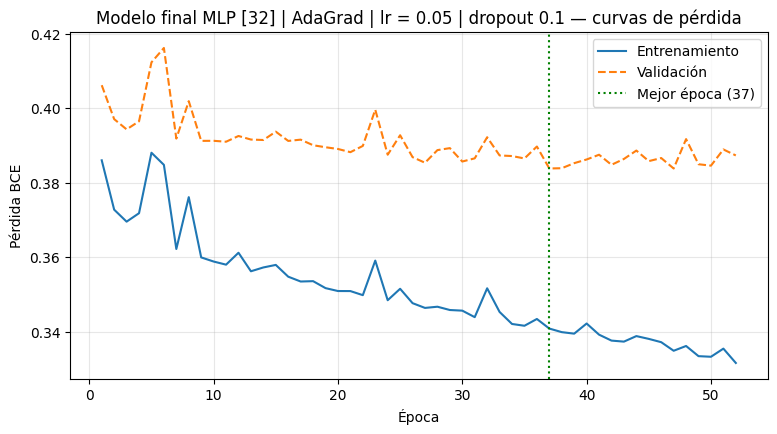

In [15]:
h = info["historial"]
plt.figure(figsize=(9, 4.5))
plt.plot(range(1, len(h["train_loss"]) + 1), h["train_loss"], label="Entrenamiento")
plt.plot(range(1, len(h["val_loss"]) + 1), h["val_loss"], "--", label="Validación")
plt.axvline(info["mejor_epoca"], color="green", linestyle=":", label=f"Mejor época ({info['mejor_epoca']})")
plt.xlabel("Época")
plt.ylabel("Pérdida BCE")
plt.title("Modelo final MLP [32] | AdaGrad | lr = 0.05 | dropout 0.1 — curvas de pérdida")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## 5. Evaluación en prueba

Es el único punto del pipeline que usa el conjunto de prueba. El modelo final se evalúa con su umbral de 0.40 y el perceptrón con el umbral estándar de 0.5, igual que en el notebook 4. La última columna verifica que los valores coincidan con los reportados en ese notebook.

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve

X_te, y_te = tensores["test"]
y_te_np = y_te.view(-1).numpy().astype(int)
proba_final = predecir_proba(modelo, X_te)
proba_perceptron = predecir_proba(perceptron, X_te)

metricas = {
    "Modelo final (umbral 0.40)": evaluar(y_te_np, proba_final, CFG.umbral),
    "Perceptrón (umbral 0.5)": evaluar(y_te_np, proba_perceptron, 0.5),
}
# Métricas en prueba reportadas en Entrenamiento_de_Red_Neuronal_Proyecto-4.ipynb
REPORTADAS = {
    "Modelo final (umbral 0.40)": {"accuracy": 0.8080, "precision": 0.6972, "recall": 0.8178, "f1": 0.7527, "auc": 0.8992},
    "Perceptrón (umbral 0.5)": {"accuracy": 0.8280, "precision": 0.7681, "recall": 0.7430, "f1": 0.7553, "auc": 0.9022},
}
tabla = pd.DataFrame(metricas).T.round(4)
tabla["¿Coincide con el notebook 4?"] = [
    all(round(metricas[m][k], 4) == v for k, v in REPORTADAS[m].items()) for m in tabla.index]
tabla.columns = ["Accuracy", "Precision (1)", "Recall (1)", "F1 (1)", "AUC", "¿Coincide con el notebook 4?"]
display(tabla)

,Accuracy,Precision (1),Recall (1),F1 (1),AUC,¿Coincide con el notebook 4?
Modelo final (umbral 0.40),0.808,0.6972,0.8178,0.7527,0.8992,True
Perceptrón (umbral 0.5),0.828,0.7681,0.7430,0.7553,0.9022,True


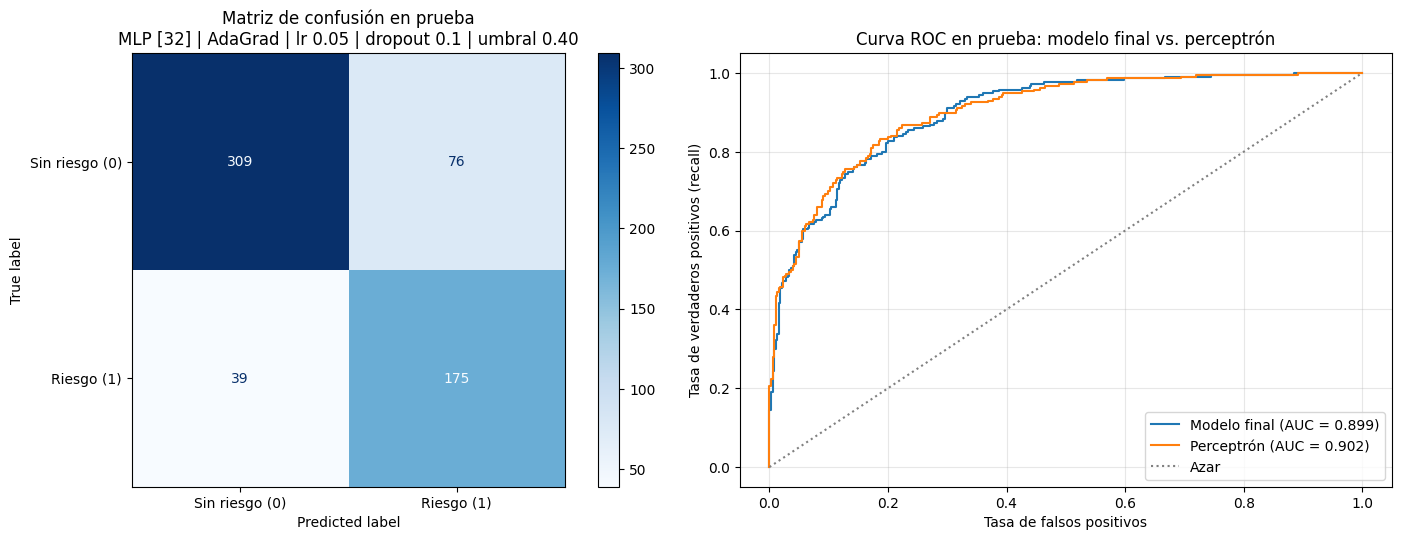

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
ConfusionMatrixDisplay.from_predictions(y_te_np, aplicar_umbral(proba_final), cmap="Blues", ax=axes[0],
                                        display_labels=["Sin riesgo (0)", "Riesgo (1)"])
axes[0].set_title("Matriz de confusión en prueba\nMLP [32] | AdaGrad | lr 0.05 | dropout 0.1 | umbral 0.40")
for nombre, proba in (("Modelo final", proba_final), ("Perceptrón", proba_perceptron)):
    fpr, tpr, _ = roc_curve(y_te_np, proba)
    axes[1].plot(fpr, tpr, label=f"{nombre} (AUC = {roc_auc_score(y_te_np, proba):.3f})")
axes[1].plot([0, 1], [0, 1], ":", color="gray", label="Azar")
axes[1].set_xlabel("Tasa de falsos positivos")
axes[1].set_ylabel("Tasa de verdaderos positivos (recall)")
axes[1].set_title("Curva ROC en prueba: modelo final vs. perceptrón")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(CFG.ruta_figuras / "evaluacion_prueba.png", dpi=150, bbox_inches="tight")
plt.show()

**Lectura de los resultados.** El modelo final detecta 175 de los 214 estudiantes en riesgo del conjunto de prueba (recall de 0.818), frente al 0.743 del perceptrón. A cambio tiene más falsas alarmas (precision de 0.697 frente a 0.768). En accuracy, F1 y AUC el perceptrón es igual o un poco mejor, porque la relación entre las variables y la etiqueta es casi lineal (ver la sección 8). Se mantiene la red porque, con el umbral de 0.40, cumple mejor el objetivo de **no dejar pasar casos en riesgo**. La diferencia de recall viene sobre todo del umbral.

## 6. Persistencia y prueba de punta a punta

Se guardan los artefactos en `modelos/` y luego se cargan **desde disco usando el módulo `src/pipeline_riesgo.py`**, sin usar nada de lo que hay en memoria en este notebook. Con ellos se predicen los registros de prueba **en su forma cruda**, tal como vienen en el CSV, pasando por `predecir()`. Si el pipeline está bien construido, las métricas deben ser exactamente las mismas de la sección 5.

In [18]:
guardar_artefactos(modelo, escalador, COLUMNAS, {k: round(v, 4) for k, v in metricas["Modelo final (umbral 0.40)"].items()})
for archivo in sorted(CFG.ruta_modelos.iterdir()):
    print(f"{archivo.name:<28} {archivo.stat().st_size / 1024:6.1f} KB")

escalador_minmax.joblib         2.5 KB
metadatos.json                  1.6 KB
mlp_final_state_dict.pt         7.0 KB


In [19]:
# Carga independiente: el módulo de src/ no comparte variables con este notebook
sys.path.insert(0, str(RAIZ))
import src.pipeline_riesgo as pr

artefactos = pr.cargar_artefactos()

# Cinco registros crudos de prueba (columnas originales del CSV, sin la etiqueta)
indices_prueba = conjuntos["test"][0].index
registros = df_crudo.loc[indices_prueba[:5]].drop(columns=df_crudo.columns[-1])
resultado = pr.predecir(registros, artefactos)
resultado["clase real"] = df.loc[resultado.index, OBJETIVO]
display(resultado.round(4))

,probabilidad_riesgo,clase,clase real
994,0.8835,1,1
430,0.8083,1,1
1897,0.0310,0,0
2538,0.0673,0,0
611,0.1298,0,1


In [20]:
# Todo el conjunto de prueba en forma cruda -> mismas métricas que la sección 5
pred_crudo = pr.predecir(df_crudo.loc[indices_prueba].drop(columns=df_crudo.columns[-1]), artefactos)
metricas_crudo = pr.evaluar(df.loc[indices_prueba, OBJETIVO].values, pred_crudo["probabilidad_riesgo"].values,
                            artefactos["umbral"])
comparacion = pd.DataFrame({"Pipeline en memoria": metricas["Modelo final (umbral 0.40)"],
                            "Inferencia desde disco (registros crudos)": metricas_crudo,
                            "Reportado en el notebook 4": REPORTADAS["Modelo final (umbral 0.40)"]}).round(4)
display(comparacion)
assert all(round(metricas_crudo[k], 4) == v for k, v in REPORTADAS["Modelo final (umbral 0.40)"].items())
print("Prueba de punta a punta superada: la inferencia sobre registros crudos reproduce las métricas reportadas.")

,Pipeline en memoria,Inferencia desde disco (registros crudos),Reportado en el notebook 4
accuracy,0.8080,0.8080,0.8080
precision,0.6972,0.6972,0.6972
recall,0.8178,0.8178,0.8178
f1,0.7527,0.7527,0.7527
auc,0.8992,0.8992,0.8992


Prueba de punta a punta superada: la inferencia sobre registros crudos reproduce las métricas reportadas.


Un registro nuevo se puede predecir como un diccionario con las columnas originales del CSV. Por ejemplo, para el primer estudiante de prueba:

In [21]:
registro_nuevo = df_crudo.loc[indices_prueba[0]].drop(df_crudo.columns[-1]).to_dict()
print(pr.predecir(registro_nuevo, artefactos))

   probabilidad_riesgo  clase
0             0.883451      1


## 7. Trazabilidad: por qué cada etapa es como es

| Etapa | Decisión | Hallazgo que la justifica (notebook 4) |
|---|---|---|
| 3. Limpieza | Eliminar `educ_padre` y `educ_madre` | 954 y 1059 faltantes de 2992 (> 30 %), no imputables (MNAR) |
| 4. Codificación | One-hot de `etnia` | Códigos 1–6 sin orden; tratarlos como números inventaría un orden falso |
| 5. Partición | Validación separada **antes** de escalar y estratificada | Antes el escalador se ajustaba con filas de validación (fuga de información) |
| 6. Escalado | MinMax ajustado solo con entrenamiento | Sin escalar: F1 = 0 (la red predice solo la clase 0). MinMax: menor pérdida de validación (0.3857) |
| 7. Arquitectura | `[32]`, la red más pequeña | Las redes grandes no mejoran y tienen más brecha y oscilación (0.047–0.057 frente a 0.043) |
| 7. Early stopping | Paciencia 15 y restaurar la mejor época | Sin él, `[128, 128, 128]` llega a una brecha de 0.1622; con él baja a 0.0177 |
| 7. Optimizador y lr | AdaGrad, lr = 0.05 | Mayor F1 de validación del grid de 216 corridas (0.7706) |
| 7. Dropout | 0.1 | Mejor F1 que sin dropout en la misma configuración (0.7706 frente a 0.7492) |
| 7. Regularización L1/L2 | No se usa | En el grid no mejoró el F1 (Ninguna 0.7531, L2 0.7523, L1 0.7488) |
| 8. Umbral | 0.40, elegido en validación | Recall bajo de la clase en riesgo (0.7193 con umbral 0.5); el ajuste de umbral subió el recall a 0.8246 en validación |
| 9. Evaluación | Prueba usada una sola vez, comparación con el perceptrón | Evitar el sesgo de selección; el perceptrón es una referencia exigente (accuracy de 0.828) |

## 8. Limitaciones

- **La etiqueta no es un diagnóstico clínico.** `riesgo_dep` se construyó con k-means sobre las respuestas del PHQ-9. Es una agrupación estadística de riesgo, no una evaluación hecha por un profesional.
- **Circularidad parcial.** El PHQ-9 no está entre las entradas, pero sí escalas muy cercanas: PSS-10 (estrés), GAD-7 (ansiedad) y la pregunta 12 (qué tan deprimido se sintió ayer). Parte del buen desempeño puede venir de medir casi lo mismo que la etiqueta. Por eso un modelo lineal (el perceptrón) ya alcanza una AUC de 0.90.
- **Datos de una sola universidad y un solo año** (Universidad Icesi, 2022). No se sabe si el modelo funciona igual en otras poblaciones.
- **Uso previsto: apoyo, no reemplazo.** El modelo sirve para priorizar a qué estudiantes ofrecer acompañamiento. La decisión final debe tomarla un profesional de bienestar o salud mental. Con el umbral de 0.40, cerca de 3 de cada 10 alertas son falsos positivos y casi 2 de cada 10 estudiantes en riesgo no se detectan.